# Meridian City FC — Exploratory Data Analysis

Business Intelligence exploratory pass over two seasons of ticketing, CRM, and marketing data.
This notebook works directly against the SQLite warehouse (`database/ticket_sales.db`) produced by the ETL pipeline
(`etl/generate_data.py` -> `validate.py` -> `clean.py` -> `transform.py` -> `load_database.py`).

Sections:
1. Setup & data load
2. Distributions (revenue, price, age)
3. Correlation heatmap
4. Monthly attendance & revenue trends
5. Customer demographics
6. Seat section popularity & ticket type mix
7. Promotion effectiveness
8. Attendance distribution & sell-through


In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from analytics.db_utils import read_table

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)

customers = read_table('customers')
games = read_table('games')
ticket_sales = read_table('ticket_sales')
campaigns = read_table('marketing_campaigns')
merchandise = read_table('merchandise')

ticket_sales['PurchaseDate'] = pd.to_datetime(ticket_sales['PurchaseDate'])
games['Date'] = pd.to_datetime(games['Date'])

print(f"Customers: {len(customers):,} | Games: {len(games):,} | Ticket sales: {len(ticket_sales):,} | Merch rows: {len(merchandise):,}")


Customers: 18,000 | Games: 84 | Ticket sales: 99,999 | Merch rows: 40,226


## 1. Distributions

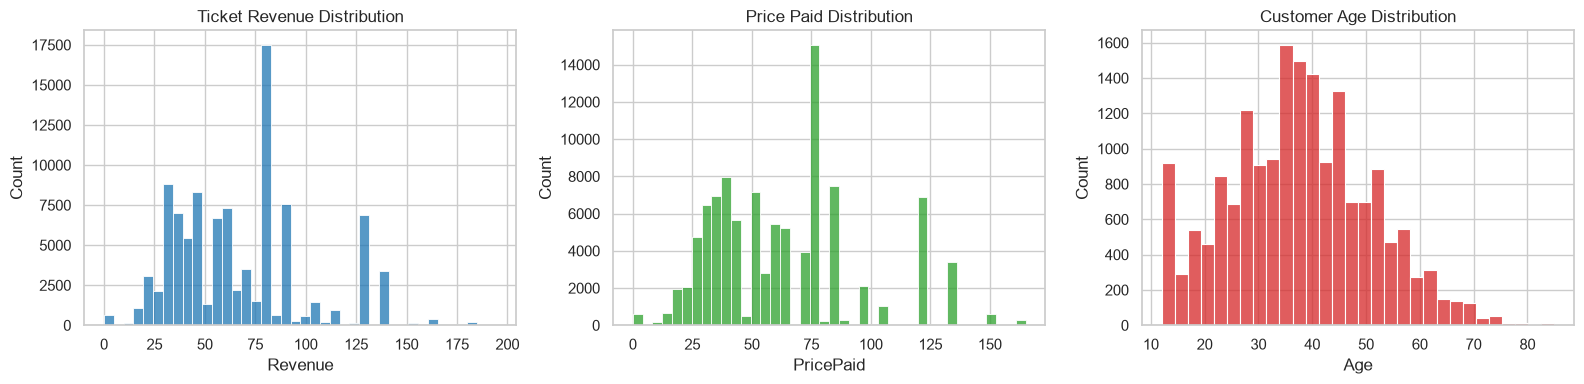

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(ticket_sales['Revenue'], bins=40, ax=axes[0], color='#1f77b4')
axes[0].set_title('Ticket Revenue Distribution')

sns.histplot(ticket_sales['PricePaid'], bins=40, ax=axes[1], color='#2ca02c')
axes[1].set_title('Price Paid Distribution')

sns.histplot(customers['Age'], bins=30, ax=axes[2], color='#d62728')
axes[2].set_title('Customer Age Distribution')
plt.tight_layout()
plt.show()


## 2. Correlation Heatmap — Game-Level Demand Drivers

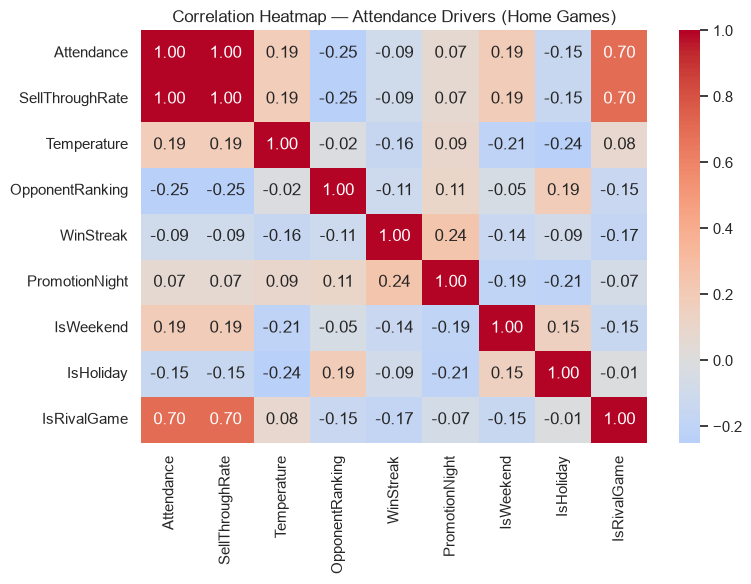

In [3]:
home_games = games[games['HomeAway'] == 'Home'].copy()
for col in ['PromotionNight', 'IsWeekend', 'IsHoliday', 'IsRivalGame']:
    home_games[col] = home_games[col].astype(int)

corr_cols = ['Attendance', 'SellThroughRate', 'Temperature', 'OpponentRanking',
             'WinStreak', 'PromotionNight', 'IsWeekend', 'IsHoliday', 'IsRivalGame']
corr = home_games[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap — Attendance Drivers (Home Games)')
plt.tight_layout()
plt.show()


## 3. Monthly Attendance & Revenue Trends

In [4]:
ticket_sales['PurchaseMonth'] = ticket_sales['PurchaseDate'].dt.to_period('M').astype(str)
monthly_revenue = ticket_sales.groupby('PurchaseMonth')['Revenue'].sum().reset_index()

fig = px.line(monthly_revenue, x='PurchaseMonth', y='Revenue', markers=True,
              title='Monthly Ticket Revenue Trend')
fig.update_layout(xaxis_tickangle=-45)
fig.show()


In [5]:
home_games['GameMonth'] = home_games['Date'].dt.to_period('M').astype(str)
monthly_attendance = home_games.groupby('GameMonth')['Attendance'].mean().reset_index()

fig = px.bar(monthly_attendance, x='GameMonth', y='Attendance',
             title='Average Home Game Attendance by Month')
fig.update_layout(xaxis_tickangle=-45)
fig.show()


## 4. Customer Demographics

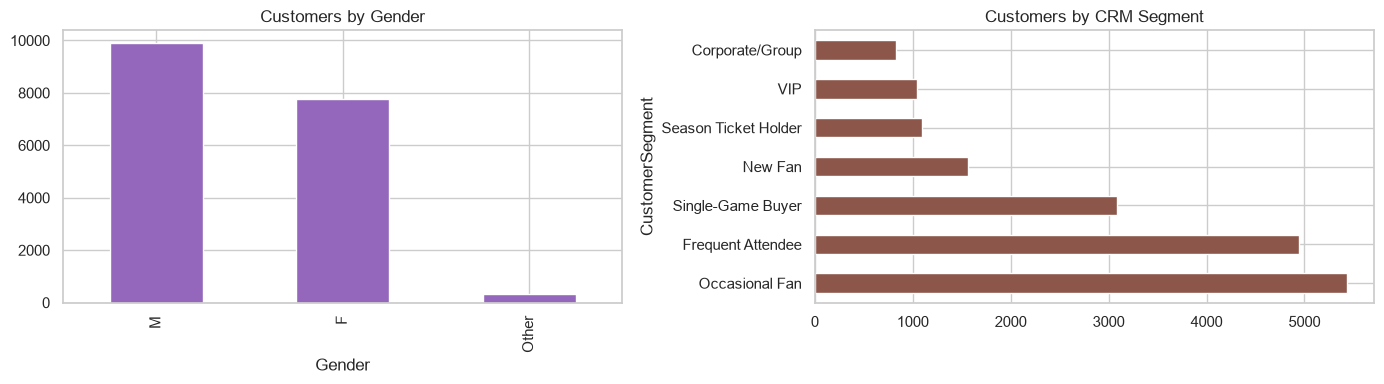

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
customers['Gender'].value_counts().plot(kind='bar', ax=axes[0], color='#9467bd')
axes[0].set_title('Customers by Gender')

customers['CustomerSegment'].value_counts().plot(kind='barh', ax=axes[1], color='#8c564b')
axes[1].set_title('Customers by CRM Segment')
plt.tight_layout()
plt.show()


In [7]:
top_states = customers['State'].value_counts().head(10)
fig = px.bar(top_states, title='Top 10 Fan States by Customer Count',
             labels={'value': 'Customers', 'index': 'State'})
fig.show()


## 5. Seat Section Popularity & Ticket Type Mix

In [8]:
section_summary = ticket_sales.groupby('SeatSection').agg(
    Tickets=('TicketID', 'count'), Revenue=('Revenue', 'sum')
).reset_index().sort_values('Revenue', ascending=False)

fig = px.bar(section_summary, x='SeatSection', y='Revenue', color='Tickets',
             title='Revenue by Seat Section')
fig.show()


In [9]:
ticket_type_summary = ticket_sales['TicketType'].value_counts(normalize=True).mul(100).round(1)
fig = px.pie(values=ticket_type_summary.values, names=ticket_type_summary.index,
             title='Ticket Type Mix (%)')
fig.show()


## 6. Promotion Effectiveness

In [10]:
promo_summary = home_games.groupby('PromotionNight').agg(
    Games=('GameID', 'count'), AvgAttendance=('Attendance', 'mean'),
    AvgSellThrough=('SellThroughRate', 'mean')
).reset_index()
promo_summary['PromotionNight'] = promo_summary['PromotionNight'].map({0: 'Standard Night', 1: 'Promotion Night'})
promo_summary


,PromotionNight,Games,AvgAttendance,AvgSellThrough
0,Standard Night,34,1885.529412,0.448936
1,Promotion Night,12,1982.500000,0.472024


## 7. Attendance Distribution & Sell-Through Rate

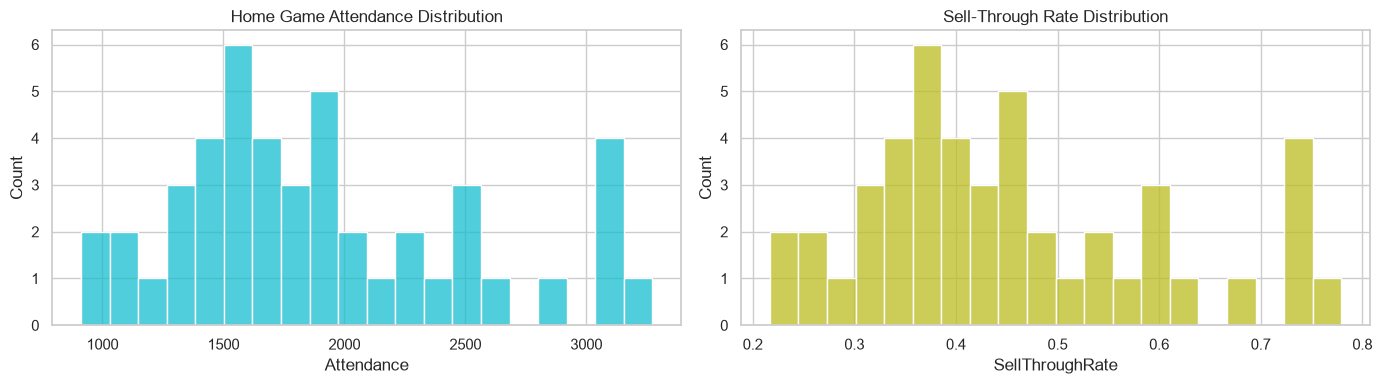

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(home_games['Attendance'], bins=20, ax=axes[0], color='#17becf')
axes[0].set_title('Home Game Attendance Distribution')

sns.histplot(home_games['SellThroughRate'], bins=20, ax=axes[1], color='#bcbd22')
axes[1].set_title('Sell-Through Rate Distribution')
plt.tight_layout()
plt.show()


## Key Takeaways

See `reports/executive_summary.md` for the full write-up of business insights derived from this analysis,
including weekend/weather/rivalry attendance effects, premium seating revenue concentration, and campaign
channel performance.
